In [1]:
# If required, uncomment and run:
# %pip install pandas numpy scikit-learn matplotlib seaborn joblib

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

RANDOM_STATE = 42
TARGET = "Condition_Class"
CLASS_NAMES = ["Excellent", "Good", "Fair", "Poor"]

In [2]:
from sklearn.model_selection import GroupShuffleSplit

# Load existing datasets
train_df = pd.read_csv("../training_image_features.csv")
val_df = pd.read_csv("../validation_image_features.csv")
test_df = pd.read_csv("../testing_image_features.csv")

# Combine all existing data
all_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Ensure every row has an image ID
all_df = all_df.dropna(subset=["Image_ID"])
all_df["Image_ID"] = all_df["Image_ID"].astype(str)

# First split: 70% train, 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(all_df, groups=all_df["Image_ID"])
)

train_df = all_df.iloc[train_idx].copy()
temp_df = all_df.iloc[temp_idx].copy()

# Second split: 15% validation, 15% test
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    split2.split(temp_df, groups=temp_df["Image_ID"])
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Save corrected datasets
train_df.to_csv("../training_image_features_grouped.csv", index=False)
val_df.to_csv("../validation_image_features_grouped.csv", index=False)
test_df.to_csv("../testing_image_features_grouped.csv", index=False)

print("Corrected dataset splits:")
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

# Verify image separation
train_ids = set(train_df["Image_ID"])
val_ids = set(val_df["Image_ID"])
test_ids = set(test_df["Image_ID"])

print("\nImage overlap:")
print("Train-Val:", len(train_ids & val_ids))
print("Train-Test:", len(train_ids & test_ids))
print("Val-Test:", len(val_ids & test_ids))

Corrected dataset splits:
Training: (11465, 43)
Validation: (2410, 43)
Testing: (2644, 43)

Image overlap:
Train-Val: 0
Train-Test: 0
Val-Test: 0


In [3]:
TRAIN_PATH = "../training_image_features_grouped.csv"
VAL_PATH   = "../validation_image_features_grouped.csv"
TEST_PATH  = "../testing_image_features_grouped.csv"

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

EXCLUDE_COLUMNS = [
    TARGET,
    "Sample_ID",
    "Image_ID",
    "Condition_Score",
    "Damage_Score",
    "Alternative_Use_Suitability",
    "Structural_Integrity",
    "Recovery_Pathway",
    "Reconditioning_Required",
    "Recovery_Potential",
    "Alternative_Use_Category",
    "pixel_img_width",
    "pixel_img_height"
]

# Use only columns available in the training data.
feature_columns = [c for c in train_df.columns if c not in EXCLUDE_COLUMNS]

X_train = train_df[feature_columns].copy()
y_train = train_df[TARGET].astype(str)

X_val = val_df[feature_columns].copy()
y_val = val_df[TARGET].astype(str)

X_test = test_df[feature_columns].copy()
y_test = test_df[TARGET].astype(str)

numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in feature_columns if c not in numeric_features]

print("Number of features:", len(feature_columns))
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("\\nFeatures used:")
print(feature_columns)

Number of features: 30
Numeric features: 24
Categorical features: 6
\nFeatures used:
['Material_Type', 'Material_Subtype', 'Source', 'Exposure_Type', 'Crack_Level', 'Surface_Damage', 'Breakage_Level', 'Discoloration_Level', 'Deformation_Level', 'Missing_Portion', 'pixel_obj_width', 'pixel_obj_height', 'relative_area', 'edge_density', 'fill_ratio', 'color_std', 'mean_brightness', 'std_brightness', 'contrast', 'texture_laplacian_var', 'dark_pixel_ratio', 'bright_pixel_ratio', 'mean_hue', 'mean_saturation', 'saturation_std', 'contour_area', 'contour_perimeter', 'circularity', 'solidity', 'extent']


In [4]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [5]:
depth_options = [3, 5, 8, 12, 16, 20, None]
validation_results = []
candidate_pipelines = {}

for depth in depth_options:
    cart_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            criterion="gini",
            max_depth=depth,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])

    cart_pipeline.fit(X_train, y_train)
    val_predictions = cart_pipeline.predict(X_val)

    macro_f1 = f1_score(y_val, val_predictions, average="macro", zero_division=0)
    accuracy = accuracy_score(y_val, val_predictions)

    validation_results.append({
        "max_depth": str(depth),
        "validation_accuracy": accuracy,
        "validation_macro_f1": macro_f1
    })
    candidate_pipelines[depth] = cart_pipeline

validation_results_df = pd.DataFrame(validation_results).sort_values(
    "validation_macro_f1", ascending=False
)
display(validation_results_df)

best_depth_label = validation_results_df.iloc[0]["max_depth"]
best_depth = None if best_depth_label == "None" else int(best_depth_label)
print("Selected max_depth:", best_depth)

,max_depth,validation_accuracy,validation_macro_f1
2,8,0.996266,0.990964
3,12,0.996680,0.985529
4,16,0.996680,0.985529
5,20,0.996680,0.985529
6,None,0.996680,0.985529
1,5,0.916183,0.901918
0,3,0.814523,0.697731


Selected max_depth: 8


In [6]:
X_train_val = pd.concat([X_train, X_val], axis=0)
y_train_val = pd.concat([y_train, y_val], axis=0)

cart_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=best_depth,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

cart_model.fit(X_train_val, y_train_val)
print("Final CART model trained.")

Final CART model trained.


In [7]:
y_test_pred = cart_model.predict(X_test)

print("CART Test Results")
print("-----------------")
print("Accuracy :", round(accuracy_score(y_test, y_test_pred), 4))
print("Precision (macro):", round(precision_score(y_test, y_test_pred, average="macro", zero_division=0), 4))
print("Recall (macro)   :", round(recall_score(y_test, y_test_pred, average="macro", zero_division=0), 4))
print("F1-score (macro) :", round(f1_score(y_test, y_test_pred, average="macro", zero_division=0), 4))

print("\\nClassification Report:")
print(classification_report(
    y_test, y_test_pred,
    labels=CLASS_NAMES,
    zero_division=0
))

CART Test Results
-----------------
Accuracy : 0.997
Precision (macro): 0.9883
Recall (macro)   : 0.9821
F1-score (macro) : 0.9851
\nClassification Report:
              precision    recall  f1-score   support

   Excellent       0.97      0.94      0.95        32
        Good       0.99      1.00      1.00       586
        Fair       1.00      1.00      1.00      1788
        Poor       0.99      1.00      0.99       238

    accuracy                           1.00      2644
   macro avg       0.99      0.98      0.99      2644
weighted avg       1.00      1.00      1.00      2644



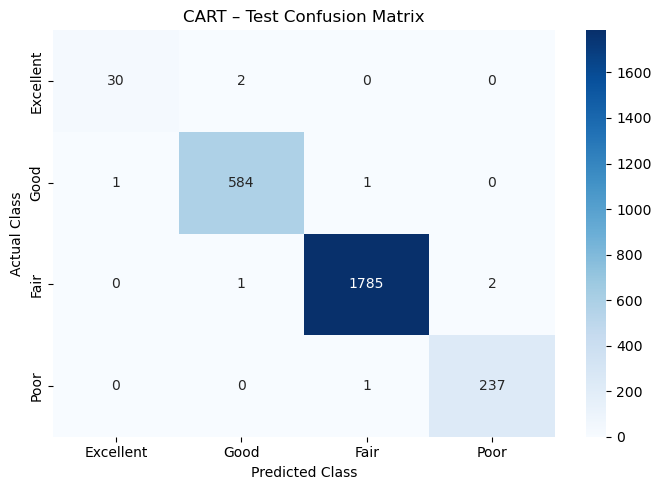

In [8]:
cm = confusion_matrix(y_test, y_test_pred, labels=CLASS_NAMES)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CART – Test Confusion Matrix")
plt.tight_layout()
plt.show()

,Feature,Importance
3,num__Deformation_Level,3.790683e-01
0,num__Crack_Level,2.474555e-01
8,num__fill_ratio,2.406839e-01
7,num__edge_density,5.470521e-02
45,cat__Missing_Portion_Severe,4.113013e-02
44,cat__Missing_Portion_Medium,2.847915e-02
2,num__Breakage_Level,6.570316e-03
10,num__mean_brightness,1.469179e-03
43,cat__Missing_Portion_Low,2.156717e-04
23,num__extent,1.367987e-04


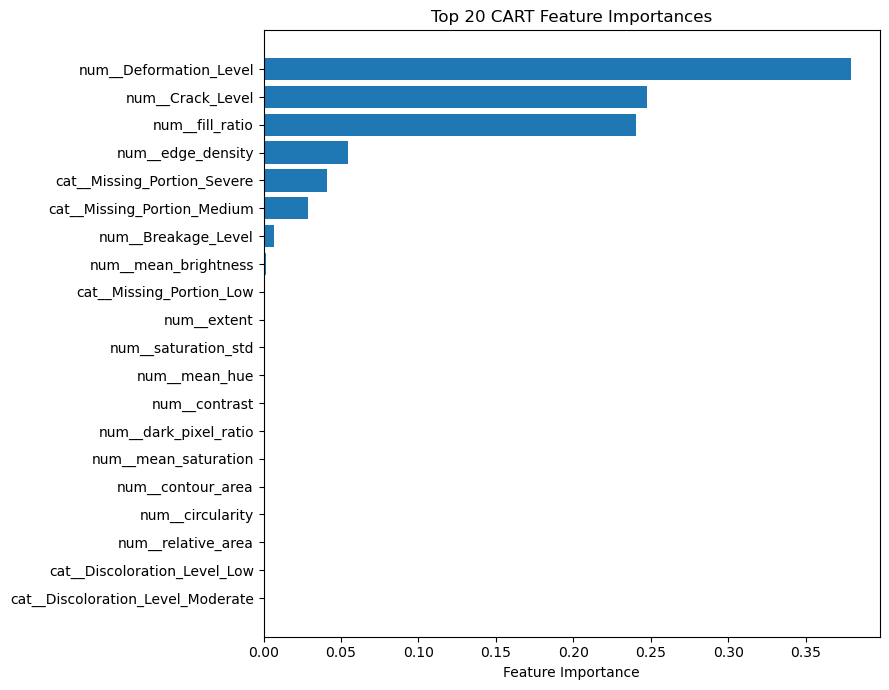

In [9]:
# Retrieve transformed feature names and CART feature importances.
fitted_preprocessor = cart_model.named_steps["preprocessor"]
tree_classifier = cart_model.named_steps["classifier"]

try:
    transformed_names = fitted_preprocessor.get_feature_names_out()
    importances = tree_classifier.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": transformed_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False)

    display(importance_df.head(20))

    top_features = importance_df.head(20).sort_values("Importance")
    plt.figure(figsize=(9, 7))
    plt.barh(top_features["Feature"], top_features["Importance"])
    plt.xlabel("Feature Importance")
    plt.title("Top 20 CART Feature Importances")
    plt.tight_layout()
    plt.show()
except Exception as error:
    print("Could not display feature names:", error)

In [40]:
print("FEATURES USED:")
print(feature_columns)

FEATURES USED:
['Sample_ID', 'Image_ID', 'Material_Type', 'Material_Subtype', 'Source', 'Exposure_Type', 'Crack_Level', 'Surface_Damage', 'Breakage_Level', 'Discoloration_Level', 'Deformation_Level', 'Missing_Portion', 'Damage_Score', 'Condition_Score', 'Structural_Integrity', 'Recovery_Pathway', 'Reconditioning_Required', 'Recovery_Potential', 'Alternative_Use_Category', 'Alternative_Use_Suitability', 'pixel_img_width', 'pixel_img_height']


In [41]:
print("Train-Val:", len(set(train_df.Image_ID) & set(val_df.Image_ID)))
print("Train-Test:", len(set(train_df.Image_ID) & set(test_df.Image_ID)))
print("Val-Test:", len(set(val_df.Image_ID) & set(test_df.Image_ID)))

Train-Val: 0
Train-Test: 0
Val-Test: 0


In [42]:
for col in [
    "Material_Type",
    "Material_Subtype",
    "Source",
    "Exposure_Type",
    "Crack_Level",
    "Surface_Damage",
    "Breakage_Level",
    "Discoloration_Level",
    "Deformation_Level",
    "Missing_Portion"
]:
    print(f"\n{col}:")
    print(train_df.groupby(col)["Condition_Class"].nunique().sort_values(ascending=False).head(10))


Material_Type:
Material_Type
brick           4
concrete        4
foam            4
general_w       4
gypsum_board    4
pipes           4
plastic         4
stone           4
tile            4
wood            4
Name: Condition_Class, dtype: int64

Material_Subtype:
Material_Subtype
Reinforced    4
Standard      4
Treated       4
Name: Condition_Class, dtype: int64

Source:
Source
Demolition_Site    4
Name: Condition_Class, dtype: int64

Exposure_Type:
Exposure_Type
Exterior_Weathered    4
Name: Condition_Class, dtype: int64

Crack_Level:
Crack_Level
1    3
2    3
3    3
4    3
5    3
Name: Condition_Class, dtype: int64

Surface_Damage:
Surface_Damage
3.0    4
3.2    4
2.0    4
2.2    4
2.5    4
2.8    4
3.8    3
3.5    3
1.0    3
1.2    3
Name: Condition_Class, dtype: int64

Breakage_Level:
Breakage_Level
1    3
2    3
3    3
4    3
5    3
Name: Condition_Class, dtype: int64

Discoloration_Level:
Discoloration_Level
High        4
Low         4
Moderate    4
Name: Condition_Class, dtype:

In [43]:
os.makedirs("saved_models", exist_ok=True)

MODEL_PATH = os.path.join("saved_models", "codd_cart_pipeline.joblib")
joblib.dump(cart_model, MODEL_PATH)

print("Saved CART pipeline to:", MODEL_PATH)
print("Use this complete pipeline during ensemble integration so preprocessing is preserved.")

Saved CART pipeline to: saved_models\codd_cart_pipeline.joblib
Use this complete pipeline during ensemble integration so preprocessing is preserved.


In [44]:
import pandas as pd

train_features = train_df[feature_columns].copy()
test_features = test_df[feature_columns].copy()

train_features = train_features.drop_duplicates()

overlap = test_features.merge(
    train_features,
    how="inner"
)

print("Identical feature rows across splits:", len(overlap))
print("Total test rows:", len(test_features))

Identical feature rows across splits: 0
Total test rows: 2644


In [45]:
from sklearn.metrics import confusion_matrix

y_pred = cart_model.predict(X_test)

print("Actual labels:")
print(y_test.value_counts())

print("\nPredicted labels:")
print(pd.Series(y_pred).value_counts())

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Actual labels:
Condition_Class
Fair         1788
Good          586
Poor          238
Excellent      32
Name: count, dtype: int64

Predicted labels:
Fair         1788
Good          586
Poor          238
Excellent      32
Name: count, dtype: int64

Confusion Matrix:
[[  32    0    0    0]
 [   0 1788    0    0]
 [   0    0  586    0]
 [   0    0    0  238]]
